<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes
After example 1 (Yes): ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
After example 2 (Yes): ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
After example 3 (No): ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
After example 4 (Yes): ['Sunny', 'Warm', '?', 'Strong', '?', '?']

Most specific hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


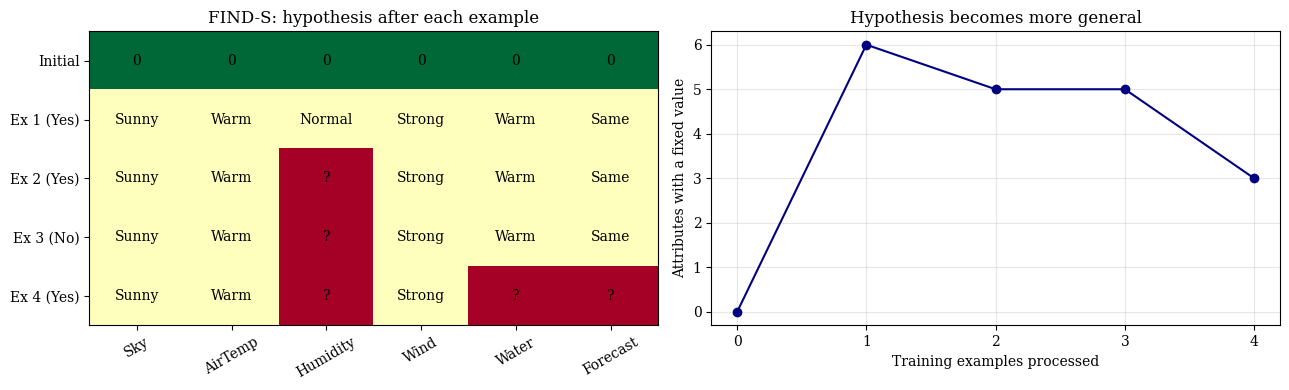

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["font.family"] = "serif"

# Training data stored in a CSV file (used by Program 1 and 2)
csv_text = """Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
Sunny,Warm,Normal,Strong,Warm,Same,Yes
Sunny,Warm,High,Strong,Warm,Same,Yes
Rainy,Cold,High,Strong,Warm,Change,No
Sunny,Warm,High,Strong,Cool,Change,Yes
"""
with open("enjoysport.csv", "w") as f:
    f.write(csv_text)
print(pd.read_csv("enjoysport.csv"))

df = pd.read_csv("enjoysport.csv")
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
attrs = list(df.columns[:-1])

h = ["0"] * X.shape[1]            # most specific hypothesis
history = [h.copy()]
for i, (x, label) in enumerate(zip(X, y), 1):
    if label == "Yes":            # FIND-S ignores negative examples
        for j in range(len(h)):
            if h[j] == "0":
                h[j] = x[j]
            elif h[j] != x[j]:
                h[j] = "?"
    history.append(h.copy())
    print(f"After example {i} ({label}): {h}")

print("\nMost specific hypothesis:", h)

# ---- Graph: how the hypothesis changes after each example
code_map = {"0": 0, "?": 2}
grid = np.array([[code_map.get(v, 1) for v in row] for row in history])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].imshow(grid, cmap="RdYlGn_r", vmin=0, vmax=2, aspect="auto")
for r, row in enumerate(history):
    for c, v in enumerate(row):
        ax[0].text(c, r, v, ha="center", va="center", fontsize=10)
ax[0].set_xticks(range(len(attrs))); ax[0].set_xticklabels(attrs, rotation=30)
ax[0].set_yticks(range(len(history)))
ax[0].set_yticklabels(["Initial"] + [f"Ex {i} ({l})" for i, l in enumerate(y, 1)])
ax[0].set_title("FIND-S: hypothesis after each example")

constrained = [sum(v not in ("?", "0") for v in row) for row in history]
ax[1].plot(range(len(history)), constrained, "o-", color="navy")
ax[1].set_xlabel("Training examples processed")
ax[1].set_ylabel("Attributes with a fixed value")
ax[1].set_title("Hypothesis becomes more general")
ax[1].set_xticks(range(len(history))); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()